In [35]:
# import群
import os
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Hiragino Sans'  # macOS標準日本語フォント

# 解析用ライブラリ
import numpy as np
import pandas as pd
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report



import importlib
# utilsフォルダ内のモジュールをインポート
from utils import data_utils
from utils import preprocess
from utils import feature_extraction

# 修正を反映
importlib.reload(data_utils)
importlib.reload(preprocess)
importlib.reload(feature_extraction)

# 必要な関数やクラスを再度ノートブックに取り込む
from utils.data_utils import *
from utils.preprocess import *
from utils.feature_extraction import *

In [36]:
# 定数
LABEL_COUNT = 18 # ラベル数
SAMPLING_RATE = 100  # サンプリングレート

data_folder = "../data/20251007"

file_paths = [f for f in os.listdir(data_folder) if f.endswith('.txt')]

file_paths.sort()

for i in range(len(file_paths)):
    print(f"{i:2}:{file_paths[i]}")

 0:20251007_083701_data.txt
 1:20251007_084040_data.txt
 2:20251007_084434_data.txt
 3:20251007_085055_data.txt
 4:20251007_085535_data.txt
 5:20251007_090435_data.txt
 6:20251007_091117_data.txt
 7:20251007_092053_data.txt
 8:20251007_092725_data.txt
 9:20251007_093215_data.txt


In [37]:
# row_data/row_csiにデータを格納する
row_data, row_csi = load_csi_data(LABEL_COUNT, data_folder, file_paths)

# 振幅と位相を分割
row_amp, row_phase = split_amp_phase(row_csi)

In [ ]:
print(len(row_csi))
print(len(row_csi[0]))
print(len(row_csi[0][0]))
print(len(row_csi[0][0][0]))
print(row_csi[0][0][0][60])

In [38]:
# ラベル数削減
def reduce_labels(row_csi, target_labels):
    """
    row_csi のラベルを target_labels に基づいて削減する。

    Args:
        row_csi: 元のデータ [ラベル][ファイル][行][サブキャリア値]
        target_labels: ラベルのグループ化を指定するリスト
                      例: [[0], [1], [2], [9], [10], [11]]

    Returns:
        reduced_row_csi: ラベル削減後のデータ
    """
    reduced_row_csi = []

    for group in target_labels:
        # グループ内のラベルを統合
        merged_group = []
        for label in group:
            merged_group.extend(row_csi[label])
        reduced_row_csi.append(merged_group)

    return reduced_row_csi

# 使用例
target_labels = [[0], [1], [2], [9], [10], [11]]
reduced_row_csi = reduce_labels(row_csi, target_labels)

# 結果の確認
print("元のラベル数:", len(row_csi))
print("削減後のラベル数:", len(reduced_row_csi))
for i, label_data in enumerate(reduced_row_csi):
    print(f"ラベル {i} のデータ数: {len(label_data)}")

元のラベル数: 18
削減後のラベル数: 6
ラベル 0 のデータ数: 10
ラベル 1 のデータ数: 10
ラベル 2 のデータ数: 10
ラベル 3 のデータ数: 10
ラベル 4 のデータ数: 10
ラベル 5 のデータ数: 10


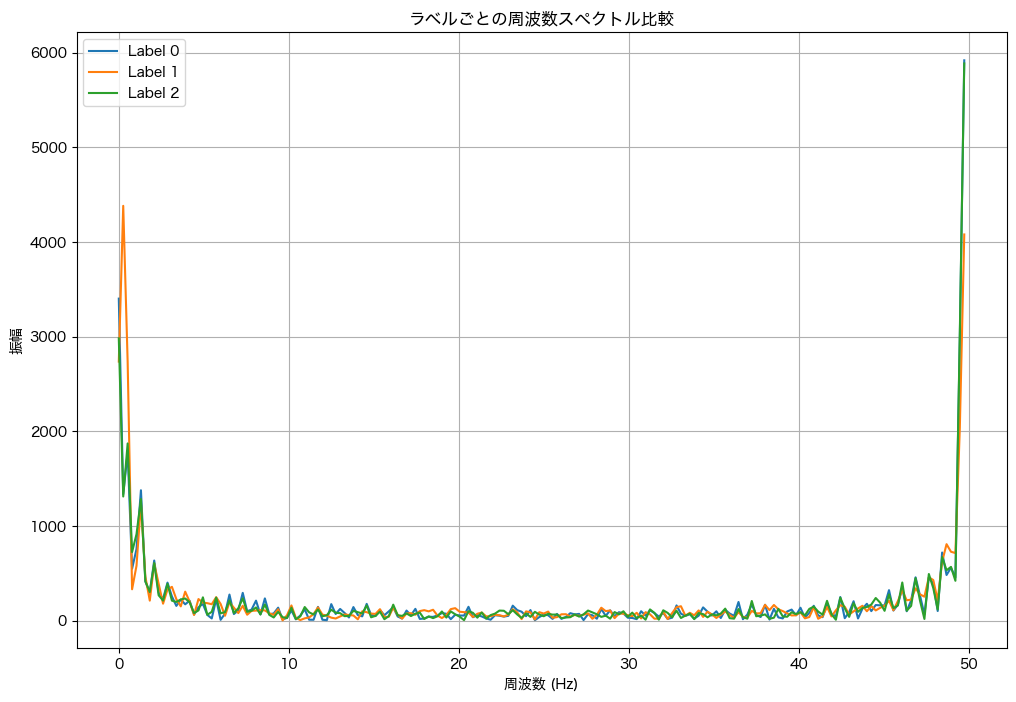

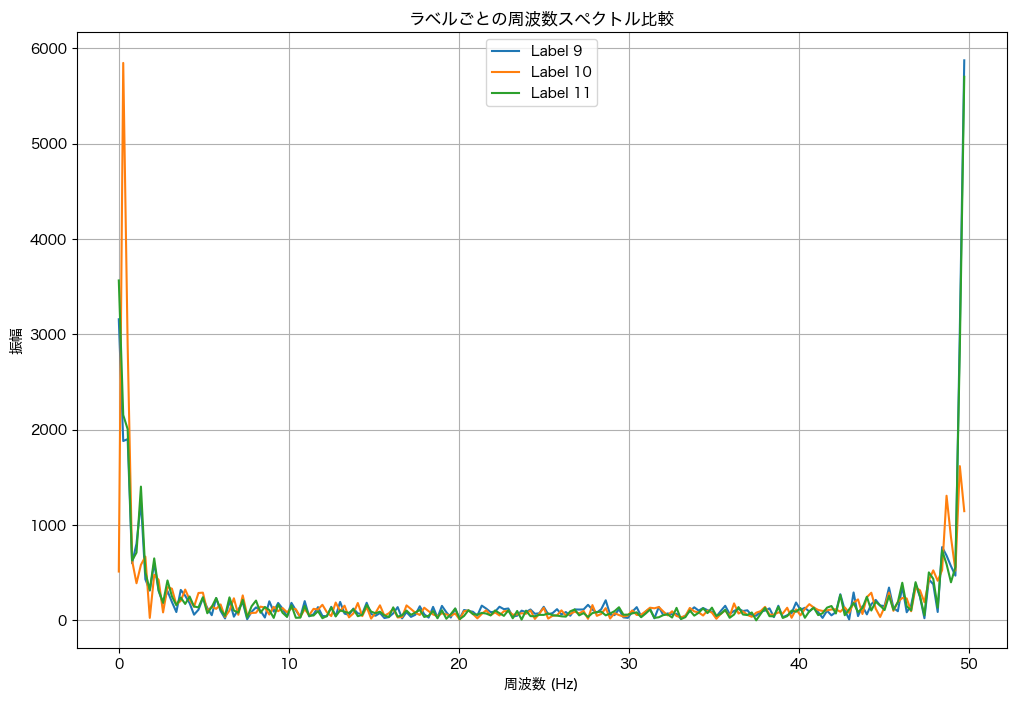

In [39]:
# ラベルごとにフーリエ変換を描画・比較する関数
import numpy as np
import matplotlib.pyplot as plt

def compare_fft_by_labels(row_csi, sampling_rate, label_indices):
    """
    複数のラベルに対してフーリエ変換を適用し、周波数スペクトルを比較する

    Args:
        row_csi: [ラベル][ファイル][行][サブキャリア値]
        sampling_rate: サンプリングレート（Hz）
        label_indices: 比較するラベルのインデックスリスト
    """
    plt.figure(figsize=(12, 8))

    for label_idx in label_indices:
        # 任意のファイルと行を選択
        file_idx = 0
        row_idx = 0

        # サンプルデータを取得
        sample_data = row_csi[label_idx][file_idx][row_idx]

        # フーリエ変換
        fft_result = np.fft.fft(sample_data)
        freqs = np.fft.fftfreq(len(sample_data), d=1/sampling_rate)
        amplitude = np.abs(fft_result)

        # プロット
        plt.plot(freqs[:len(freqs)//2], amplitude[:len(amplitude)//2], label=f"Label {label_idx}")

    plt.title("ラベルごとの周波数スペクトル比較")
    plt.xlabel("周波数 (Hz)")
    plt.ylabel("振幅")
    plt.legend()
    plt.grid()
    plt.show()

# 使用例: ラベル0, 1, 2を比較
compare_fft_by_labels(row_csi, SAMPLING_RATE, label_indices=[0, 1, 2])
compare_fft_by_labels(row_csi, SAMPLING_RATE, label_indices=[9, 10, 11])

In [89]:
def extract_stft_features(csi_segment, sampling_rate):
    """
    CSIデータのSTFT特徴を抽出（振幅スペクトログラム）
    csi_segment: shape = (samples, subcarriers)
    """
    n_samples, n_subcarriers = csi_segment.shape
    features = []

    for i in range(n_subcarriers):
        amplitude = np.abs(csi_segment[:, i])

        # ハニング窓でSTFT
        f, t, Zxx = signal.stft(amplitude, fs=sampling_rate, nperseg=64, noverlap=32, window='hann')

        # パワースペクトルに変換
        power_spectrum = np.abs(Zxx) ** 2

        # 低周波（0〜10Hz）に限定
        freq_mask = (f >= 0) & (f <= 10)
        power_spectrum = power_spectrum[freq_mask, :]

        # 各周波数帯の平均パワーを特徴量とする
        features.append(np.mean(power_spectrum, axis=1))

    # サブキャリア方向に結合
    return np.concatenate(features)

In [90]:
# --- row_csi から特徴量抽出 ---
X = []  # 特徴量ベクトル
y = []  # ラベル

for label_idx, label_data in enumerate(reduced_row_csi):  # 各ラベル
    for file_data in label_data:  # 各ファイル
        csi_segment = np.array(file_data)  # shape = (samples, subcarriers)
        
        # 特徴抽出
        features = extract_stft_features(csi_segment, SAMPLING_RATE)
        
        # 保存
        X.append(features)
        y.append(label_idx)

X = np.array(X)
y = np.array(y)

print("特徴量配列の形状:", y.shape)
print("ラベル数:", len(y))

特徴量配列の形状: (60,)
ラベル数: 60


In [91]:
from sklearn.decomposition import PCA

print("PCA前の次元:", X.shape[1])
pca = PCA(n_components=30)
X_pca = pca.fit_transform(X)
print("PCA後の次元:", X_pca.shape[1])

PCA前の次元: 2688
PCA後の次元: 30


In [88]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, stratify=y, random_state=42
)

clf = RandomForestClassifier(n_estimators=100, random_state=0)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))


              precision    recall  f1-score   support

           0      0.333     0.500     0.400         2
           1      0.000     0.000     0.000         2
           2      0.500     0.500     0.500         2
           3      0.000     0.000     0.000         2
           4      0.000     0.000     0.000         2
           5      0.250     0.500     0.333         2

    accuracy                          0.250        12
   macro avg      0.181     0.250     0.206        12
weighted avg      0.181     0.250     0.206        12



/Users/tanakakeiji/研究コード/reserch-analysis/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/tanakakeiji/研究コード/reserch-analysis/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/tanakakeiji/研究コード/reserch-analysis/venv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(av

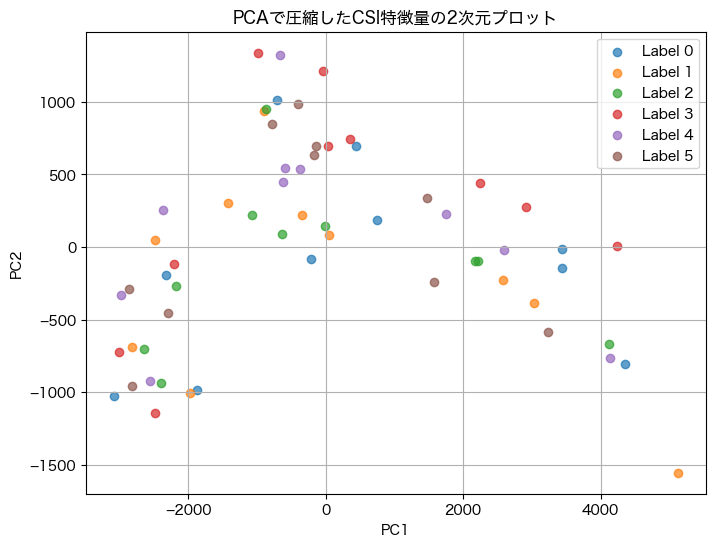

In [61]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

# X: 特徴量行列 (サンプル数, 元特徴量数)
# y: ラベル (サンプル数, )

# PCAで2次元に圧縮
pca = PCA(n_components=2)
X_pca_2d = pca.fit_transform(X)

# プロット
plt.figure(figsize=(8,6))
for label_idx in np.unique(y):
    mask = (y == label_idx)
    plt.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], label=f"Label {label_idx}", alpha=0.7)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCAで圧縮したCSI特徴量の2次元プロット")
plt.legend()
plt.grid(True)
plt.show()
